In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
!pip install torch_geometric

In [19]:
import shutil

files = ['fast_kan_conv.py', 'kan_conv.py', 'kan.py', 'layers.py', 'utils.py', '__init__.py']

for f in files:

    shutil.copy(f'/content/drive/MyDrive/GKANSU/{f}', f'/content/{f}')

print("All files copied successfully!")

All files copied successfully!


In [20]:
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torch_geometric.nn as pyg_nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from torch_geometric.data import Data, DataLoader as GeometricDataLoader
from skimage.metrics import mean_squared_error
from fast_kan_conv import FastKANConv2DLayer
from kan_conv import KANConv2DLayer

# Spatial-Spectral Attention Module
class SpatialSpectralAttention(nn.Module):
    def __init__(self, channels):
        super(SpatialSpectralAttention, self).__init__()
        self.conv1x1 = nn.Conv2d(channels, channels // 2, kernel_size=1)
        self.conv3x3 = nn.Conv2d(channels // 2, channels, kernel_size=3, padding=1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        attn = self.conv1x1(x)
        attn = self.conv3x3(attn)
        attn = self.sigmoid(attn)
        return x * attn

# Improved Graph-KAN Spectral Upsampling Model with Residual Projection
class GKANSU_Improved(nn.Module):
    def __init__(self, in_channels, out_channels, hidden_dim=128, num_gat_layers=3, img_size=(64, 64)):
        """
        :param in_channels: Number of input spectral bands (e.g., 20)
        :param out_channels: Number of output spectral bands (e.g., 200)
        :param hidden_dim: Hidden dimension for the GAT/KAN layers
        :param num_gat_layers: Number of GAT layers to stack
        :param img_size: (height, width) of each image patch
        """
        super(GKANSU_Improved, self).__init__()
        self.img_size = img_size

        # Add a projection layer to match input channels to hidden_dim
        if in_channels != hidden_dim:
            self.input_proj = nn.Linear(in_channels, hidden_dim)
        else:
            self.input_proj = nn.Identity()

        # Graph-Spectral Feature Extraction using multiple GAT layers
        self.gat_layers = nn.ModuleList()
        self.batch_norms = nn.ModuleList()

        # First GAT layer
        self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
        self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Additional GAT layers
        for _ in range(num_gat_layers - 1):
            self.gat_layers.append(pyg_nn.GATConv(hidden_dim, hidden_dim, heads=4, concat=False))
            self.batch_norms.append(nn.BatchNorm1d(hidden_dim))

        # Multiple KAN Blocks with Residual Connections
        self.fast_kan1 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)
        self.fast_kan2 = FastKANConv2DLayer(hidden_dim, hidden_dim, kernel_size=3, padding=1)

        # Spatial-Spectral Attention
        self.ssa = SpatialSpectralAttention(hidden_dim)

        # Final KAN-based Refinement
        self.final_refinement = KANConv2DLayer(hidden_dim, out_channels, kernel_size=3, padding=1)

        # Non-negativity constraint (using ReLU only)
        self.relu = nn.ReLU()

    def forward(self, x, edge_index):
        """
        :param x: Node features, shape [num_nodes, in_channels]
        :param edge_index: Graph edges (2, E)
        :return: Super-resolved output, shape [batch, out_channels, H, W]
        """
        # Project input features to hidden_dim
        x = self.input_proj(x)

        # Graph-Spectral Learning with GAT layers with skip connections
        for gat_layer, bn in zip(self.gat_layers, self.batch_norms):
            residual = x
            x = gat_layer(x, edge_index)
            x = bn(x)
            x = F.relu(x + residual)

        # Reshape from (num_nodes, hidden_dim) to (batch, hidden_dim, H, W)
        num_nodes = x.shape[0]
        batch_size = num_nodes // (self.img_size[0] * self.img_size[1])
        x = x.view(batch_size, self.img_size[0], self.img_size[1], -1)
        x = x.permute(0, 3, 1, 2)

        # Multiple KAN Blocks with skip connections
        residual = x
        x = self.fast_kan1(x)
        x = F.relu(x + residual)

        residual = x
        x = self.fast_kan2(x)
        x = F.relu(x + residual)

        # Spatial-Spectral Attention
        x = self.ssa(x)

        # Final KAN-based Refinement
        x = self.final_refinement(x)

        # Apply non-negativity constraint
        x = self.relu(x)

        return x



# Data Prep

In [21]:
# Data PRep
# Data Loading Function
def load_npy_files_from_folder(folder_path):
    npy_files = [f for f in os.listdir(folder_path) if f.endswith('.npy')]
    npy_files.sort()
    arrays = [np.load(os.path.join(folder_path, file)) for file in npy_files]
    return np.stack(arrays, axis=0)

# Paths to LR and HR Data
LR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/low_res_patches'
HR_folder_path = '/content/drive/MyDrive/GKANSU/Spectral Datasets/high_res_patches'
lr_images = load_npy_files_from_folder(LR_folder_path).astype(np.float32)
hr_images = load_npy_files_from_folder(HR_folder_path).astype(np.float32)

# ----------- NORMALIZATION -----------
# Min-Max Normalization per channel
lr_min = lr_images.min(axis=(0, 1, 2), keepdims=True)
lr_max = lr_images.max(axis=(0, 1, 2), keepdims=True)
hr_min = hr_images.min(axis=(0, 1, 2), keepdims=True)
hr_max = hr_images.max(axis=(0, 1, 2), keepdims=True)
"""
lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)
"""

lr_images = (lr_images - lr_min) / (lr_max - lr_min + 1e-8)
hr_images = (hr_images - hr_min) / (hr_max - hr_min + 1e-8)


# ── ADD AUGMENTATION HERE ──────────────────────────────────────
def augment_hsi(lr, hr):
    augmented_lr, augmented_hr = [lr], [hr]
    augmented_lr.append(np.flip(lr, axis=1).copy())
    augmented_hr.append(np.flip(hr, axis=1).copy())
    augmented_lr.append(np.flip(lr, axis=0).copy())
    augmented_hr.append(np.flip(hr, axis=0).copy())
    augmented_lr.append(np.rot90(lr, k=1).copy())
    augmented_hr.append(np.rot90(hr, k=1).copy())
    augmented_lr.append(np.rot90(lr, k=2).copy())
    augmented_hr.append(np.rot90(hr, k=2).copy())
    return augmented_lr, augmented_hr

aug_lr, aug_hr = [], []
for lr, hr in zip(lr_images, hr_images):
    lrs, hrs = augment_hsi(lr, hr)
    aug_lr.extend(lrs)
    aug_hr.extend(hrs)

lr_images = np.array(aug_lr)
hr_images = np.array(aug_hr)
print(f"After augmentation: {len(lr_images)} samples")  # should print 140
# ──────────────────────────────────────────────────────────────

# Splitting Data
from sklearn.model_selection import train_test_split
trainSL, testSL, trainSH, testSH = train_test_split(lr_images, hr_images, test_size=0.2, random_state=42)



# Function to Create Graph Data
def create_graph_from_image(image):
    H, W, C = image.shape
    num_nodes = H * W
    features = image.reshape(num_nodes, C)  # Flatten spatial dims

    edge_index = []
    for i in range(H):
        for j in range(W):
            node = i * W + j
            if i > 0: edge_index.append([node, node - W])
            if i < H - 1: edge_index.append([node, node + W])
            if j > 0: edge_index.append([node, node - 1])
            if j < W - 1: edge_index.append([node, node + 1])
    edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()

    return Data(x=torch.tensor(features, dtype=torch.float), edge_index=edge_index)

# Graph Dataset Class
class HSI_GraphDataset(Dataset):
    def __init__(self, lr_images, hr_images):
        assert len(lr_images) == len(hr_images), "LR and HR images must have the same number of samples"
        self.graphs = [create_graph_from_image(img) for img in lr_images]
        self.hr_images = [torch.tensor(img, dtype=torch.float32).permute(2, 0, 1) for img in hr_images]

    def __len__(self):
        return len(self.graphs)

    def __getitem__(self, idx):
        return self.graphs[idx], self.hr_images[idx]


After augmentation: 180 samples


In [22]:
import torch
print(torch.cuda.is_available())        # Should print True
print(torch.cuda.get_device_name(0))    # Should print T4 or similar

print(torch.cuda.get_device_name(0))  # run this before training

True
Tesla T4
Tesla T4


# Training

In [23]:
"""# Data Loaders
train_dataset = HSI_GraphDataset(trainSL, trainSH)
test_dataset = HSI_GraphDataset(testSL, testSH)
train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)
# Training for 150 epochs
'''
# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

#epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()

'''

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Custom SAM Loss Function
def sam_loss(hr, sr, eps=1e-8):
    """ """
    Compute the Spectral Angle Mapper (SAM) loss between two images.
    hr and sr should be tensors of shape [batch, channels, H, W].
    Returns the average spectral angle (in radians) over all pixels.
    """ """
    # Flatten spatial dimensions: shape [batch, channels, num_pixels]
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)

    # Compute norms along the channel dimension for each pixel
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)

    # Compute dot product between corresponding spectral vectors
    dot_product = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)

    # Compute cosine of the spectral angle and clamp for numerical stability
    cos_angle = dot_product / (hr_norm * sr_norm + eps)
    cos_angle = torch.clamp(cos_angle, -1.0, 1.0)

    # Compute the spectral angle (in radians)
    angle = torch.acos(cos_angle)

    # Average the angle over all pixels and batches
    return torch.mean(angle)

# Model Training with Early Stopping and SAM Loss
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
# Use the SAM loss instead of MSELoss
criterion = sam_loss

loss_history = []
patience = 10         # number of epochs to wait for improvement
min_delta = 1e-4      # minimum change to count as an improvement
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, SAM Loss: {avg_loss:.4f}")

    # Early Stopping Check
    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="SAM Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (radians)")
plt.title("Training SAM Loss Over Epochs")
plt.legend()
plt.show()
"""

'# Data Loaders\ntrain_dataset = HSI_GraphDataset(trainSL, trainSH)\ntest_dataset = HSI_GraphDataset(testSL, testSH)\ntrain_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)\ntest_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)\n# Training for 150 epochs\n\'\'\'\n# Model Training\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)\noptimizer = optim.Adam(model.parameters(), lr=1e-4)\ncriterion = nn.MSELoss()\n\nloss_history = []\n\n#epochs = 150\nfor epoch in range(epochs):\n    model.train()\n    epoch_loss = 0\n    for graph_data, hr_imgs in train_loader:\n        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)\n        optimizer.zero_grad()\n        sr_imgs = model(graph_data.x, graph_data.edge_index)\n        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)\n        loss.backward()\n        optimizer.step()\n        epo

/tmp/ipykernel_982/2529718413.py:4: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
/tmp/ipykernel_982/2529718413.py:5: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)


Epoch 1/150, SAM+MSE Loss: 0.6357
Epoch 2/150, SAM+MSE Loss: 0.4594
Epoch 3/150, SAM+MSE Loss: 0.3564
Epoch 4/150, SAM+MSE Loss: 0.2948
Epoch 5/150, SAM+MSE Loss: 0.2671
Epoch 6/150, SAM+MSE Loss: 0.2412
Epoch 7/150, SAM+MSE Loss: 0.2277
Epoch 8/150, SAM+MSE Loss: 0.2128
Epoch 9/150, SAM+MSE Loss: 0.2047
Epoch 10/150, SAM+MSE Loss: 0.2001
Epoch 11/150, SAM+MSE Loss: 0.1960
Epoch 12/150, SAM+MSE Loss: 0.1898
Epoch 13/150, SAM+MSE Loss: 0.1845
Epoch 14/150, SAM+MSE Loss: 0.1839
Epoch 15/150, SAM+MSE Loss: 0.1822
Epoch 16/150, SAM+MSE Loss: 0.1733
Epoch 17/150, SAM+MSE Loss: 0.1732
Early stopping trigger count: 1/10
Epoch 18/150, SAM+MSE Loss: 0.1708
Epoch 19/150, SAM+MSE Loss: 0.1714
Early stopping trigger count: 1/10
Epoch 20/150, SAM+MSE Loss: 0.1654
Epoch 21/150, SAM+MSE Loss: 0.1619
Epoch 22/150, SAM+MSE Loss: 0.1638
Early stopping trigger count: 1/10
Epoch 23/150, SAM+MSE Loss: 0.1620
Early stopping trigger count: 2/10
Epoch 24/150, SAM+MSE Loss: 0.1576
Epoch 25/150, SAM+MSE Loss: 0

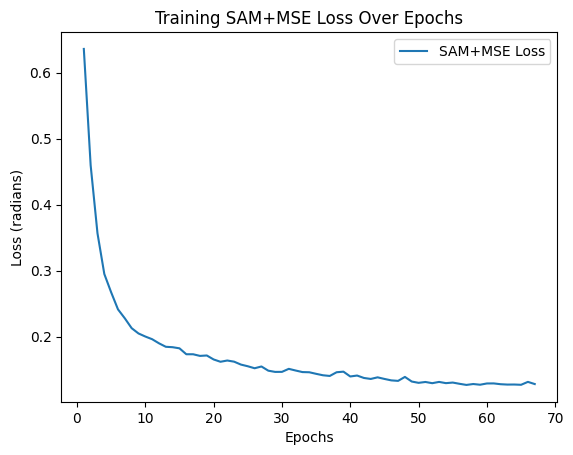

In [24]:
# Data Loaders
train_dataset = HSI_GraphDataset(trainSL, trainSH)
test_dataset = HSI_GraphDataset(testSL, testSH)
train_loader = GeometricDataLoader(train_dataset, batch_size=8, shuffle=True)
test_loader = GeometricDataLoader(test_dataset, batch_size=8, shuffle=True)
# Training for 150 epochs
'''
# Model Training
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []

#epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    loss_history.append(epoch_loss / len(train_loader))
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {loss_history[-1]:.4f}")

plt.plot(range(1, epochs + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show()

'''

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Custom SAM Loss Function
def sam_loss(hr, sr, eps=1e-8):
    """
    Compute the Spectral Angle Mapper (SAM) loss between two images.
    hr and sr should be tensors of shape [batch, channels, H, W].
    Returns the average spectral angle (in radians) over all pixels.
    """
    batch, channels, H, W = hr.shape
    hr_flat = hr.view(batch, channels, -1)
    sr_flat = sr.view(batch, channels, -1)
    hr_norm = torch.norm(hr_flat, dim=1, keepdim=True)
    sr_norm = torch.norm(sr_flat, dim=1, keepdim=True)
    dot_product = torch.sum(hr_flat * sr_flat, dim=1, keepdim=True)
    cos_angle = dot_product / (hr_norm * sr_norm + eps)
    cos_angle = torch.clamp(cos_angle, -1.0, 1.0)
    angle = torch.acos(cos_angle)
    return torch.mean(angle)

# Combined SAM + MSE Loss
def combined_loss(hr, sr, alpha=0.7, eps=1e-8):
    sam  = sam_loss(hr, sr, eps)
    mse  = F.mse_loss(sr, hr)
    return alpha * sam + (1 - alpha) * mse

# Model Training with Early Stopping and SAM+MSE Loss
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
# Use combined SAM + MSE loss instead of SAM only
criterion = combined_loss

loss_history = []
patience = 10
min_delta = 1e-4
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, SAM+MSE Loss: {avg_loss:.4f}")

    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="SAM+MSE Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss (radians)")
plt.title("Training SAM+MSE Loss Over Epochs")
plt.legend()
plt.show()

In [28]:
"""# Model Training with Early Stopping
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.MSELoss()

loss_history = []
patience = 10         # number of epochs to wait for improvement
min_delta = 1e-4      # minimum change to count as an improvement
best_loss = float('inf')
trigger_times = 0

epochs = 150
for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    for graph_data, hr_imgs in train_loader:
        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)
        optimizer.zero_grad()
        sr_imgs = model(graph_data.x, graph_data.edge_index)
        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    avg_loss = epoch_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {avg_loss:.4f}")

    # Early Stopping Check
    if best_loss - avg_loss > min_delta:
        best_loss = avg_loss
        trigger_times = 0
    else:
        trigger_times += 1
        print(f"Early stopping trigger count: {trigger_times}/{patience}")
        if trigger_times >= patience:
            print("Loss has stabilized. Stopping training early.")
            break

plt.plot(range(1, len(loss_history) + 1), loss_history, label="Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.show() """

'# Model Training with Early Stopping\ndevice = \'cuda\' if torch.cuda.is_available() else \'cpu\'\nmodel = GKANSU_Improved(in_channels=20, out_channels=200, img_size=(64, 64)).to(device)\noptimizer = optim.Adam(model.parameters(), lr=1e-4)\ncriterion = nn.MSELoss()\n\nloss_history = []\npatience = 10         # number of epochs to wait for improvement\nmin_delta = 1e-4      # minimum change to count as an improvement\nbest_loss = float(\'inf\')\ntrigger_times = 0\n\nepochs = 150\nfor epoch in range(epochs):\n    model.train()\n    epoch_loss = 0\n    for graph_data, hr_imgs in train_loader:\n        graph_data, hr_imgs = graph_data.to(device), hr_imgs.to(device)\n        optimizer.zero_grad()\n        sr_imgs = model(graph_data.x, graph_data.edge_index)\n        loss = criterion(sr_imgs.view(hr_imgs.shape), hr_imgs)\n        loss.backward()\n        optimizer.step()\n        epoch_loss += loss.item()\n\n    avg_loss = epoch_loss / len(train_loader)\n    loss_history.append(avg_loss)\n 

**SHAPKAN  Pruning**

In [29]:
# ============================================================
# DIAGNOSTIC — is the in-memory model different from the checkpoint?
# ============================================================
import torch, copy

CHECKPOINT = '/content/drive/MyDrive/GKANSU/model_checkpoint.pth'

# 1) Snapshot a few weight values from the CURRENT in-memory model
probe_before = {
    'fast_kan1.base_conv.0.weight': model.fast_kan1.base_conv[0].weight.detach().clone(),
    'fast_kan2.base_conv.0.weight': model.fast_kan2.base_conv[0].weight.detach().clone(),
}

# 2) Evaluate baseline with whatever is CURRENTLY in memory (no reload)
print("=== BASELINE — using model already in memory (no reload) ===")
baseline_current = evaluate_model_full(model, test_loader, device)
print(f"  SAM : {baseline_current['SAM']:.4f}")
print(f"  RMSE: {baseline_current['RMSE']:.4f}")

# 3) Now actually reload the checkpoint fresh
state = torch.load(CHECKPOINT, map_location=device)
model.load_state_dict(state)
model.to(device)
model.eval()

# 4) Compare weights: did reloading actually change anything?
for name, before in probe_before.items():
    after = dict(model.named_parameters())[name] if name in dict(model.named_parameters()) else None
    # fallback direct access since names above are dotted paths already matching attrs
    after = eval(f"model.{name.replace('.0.', '[0].')}").detach()
    same = torch.allclose(before, after)
    max_diff = (before - after).abs().max().item()
    print(f"{name}: identical after reload = {same}  (max abs diff = {max_diff:.6f})")

# 5) Evaluate baseline AGAIN, now on the freshly reloaded checkpoint
print("\n=== BASELINE — using freshly reloaded checkpoint ===")
baseline_reloaded = evaluate_model_full(model, test_loader, device)
print(f"  SAM : {baseline_reloaded['SAM']:.4f}")
print(f"  RMSE: {baseline_reloaded['RMSE']:.4f}")

# 6) Direct comparison
print("\n=== COMPARISON ===")
print(f"SAM  — in-memory: {baseline_current['SAM']:.4f}   reloaded: {baseline_reloaded['SAM']:.4f}   diff: {baseline_reloaded['SAM']-baseline_current['SAM']:+.4f}")
print(f"RMSE — in-memory: {baseline_current['RMSE']:.4f}   reloaded: {baseline_reloaded['RMSE']:.4f}   diff: {baseline_reloaded['RMSE']-baseline_current['RMSE']:+.4f}")

=== BASELINE — using model already in memory (no reload) ===
  SAM : 0.1604
  RMSE: 0.2781
fast_kan1.base_conv.0.weight: identical after reload = False  (max abs diff = 0.112192)
fast_kan2.base_conv.0.weight: identical after reload = False  (max abs diff = 0.126416)

=== BASELINE — using freshly reloaded checkpoint ===
  SAM : 0.2845
  RMSE: 0.1391

=== COMPARISON ===
SAM  — in-memory: 0.1604   reloaded: 0.2845   diff: +0.1240
RMSE — in-memory: 0.2781   reloaded: 0.1391   diff: -0.1390


Pre-loading calibration batch...
  Calib batch: graph.x=torch.Size([32768, 20]), hr=torch.Size([8, 200, 64, 64])
✓ Reloaded clean checkpoint from /content/drive/MyDrive/GKANSU/model_checkpoint.pth
BASELINE — before pruning
  SAM : 0.2845
  RMSE: 0.1391
  SSIM: 0.7742
  SSR : 0.2258
BASELINE — before pruning
  SAM : 0.2845
  RMSE: 0.1391
  SSIM: 0.7742
  SSR : 0.2258

ShapKAN SV — fast_kan1  (l=1, bottom-up)


ShapKAN [fast_kan1]:   0%|          | 0/8 [00:00<?, ?it/s]

  min=0.00005  max=0.04093  mean=0.00711

ShapKAN SV — fast_kan2  (l=2)


ShapKAN [fast_kan2]:   0%|          | 0/8 [00:00<?, ?it/s]

  min=0.00000  max=0.04796  mean=0.00853

Pruning Sweep
 Ratio | %Pruned |  SAM_noFT |  SAM_FT |    RMSE |    SSIM |     SSR |    ΔSAM |   ΔRMSE
--------------------------------------------------------------------------------
  [ratio=30%] Finetuning...
  [FT 1/10] loss: 0.2334
  [FT 2/10] loss: 0.1866
  [FT 3/10] loss: 0.1754
  [FT 4/10] loss: 0.1723
  [FT 5/10] loss: 0.1639
  [FT 6/10] loss: 0.1605
  [FT 7/10] loss: 0.1622
  [FT 8/10] loss: 0.1571
  [FT 9/10] loss: 0.1515
  [FT 10/10] loss: 0.1479
   30% |   30.5% |    0.4734 |  0.1941 |  0.2130 |  0.6115 |  0.3885 | -0.0904 | +0.0739
  [ratio=40%] Finetuning...
  [FT 1/10] loss: 0.2552
  [FT 2/10] loss: 0.1977
  [FT 3/10] loss: 0.1780
  [FT 4/10] loss: 0.1718
  [FT 5/10] loss: 0.1668
  [FT 6/10] loss: 0.1616
  [FT 7/10] loss: 0.1591
  [FT 8/10] loss: 0.1585
  [FT 9/10] loss: 0.1549
  [FT 10/10] loss: 0.1495
   40% |   40.6% |    0.5205 |  0.2058 |  0.2237 |  0.5850 |  0.4150 | -0.0787 | +0.0847
  [ratio=50%] Finetuning...
  [FT 1/10

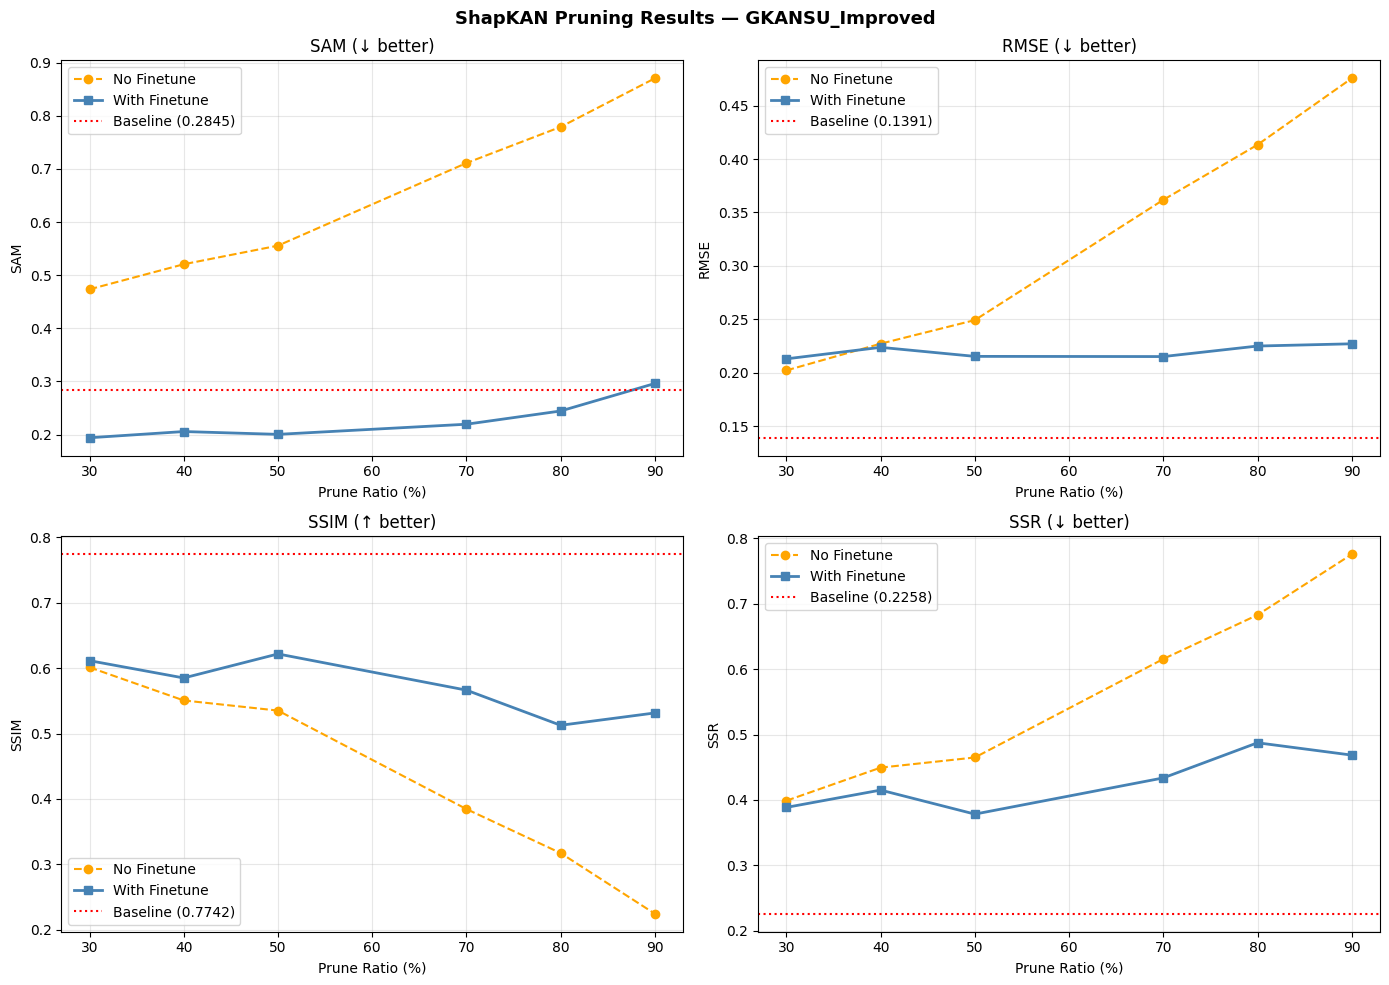

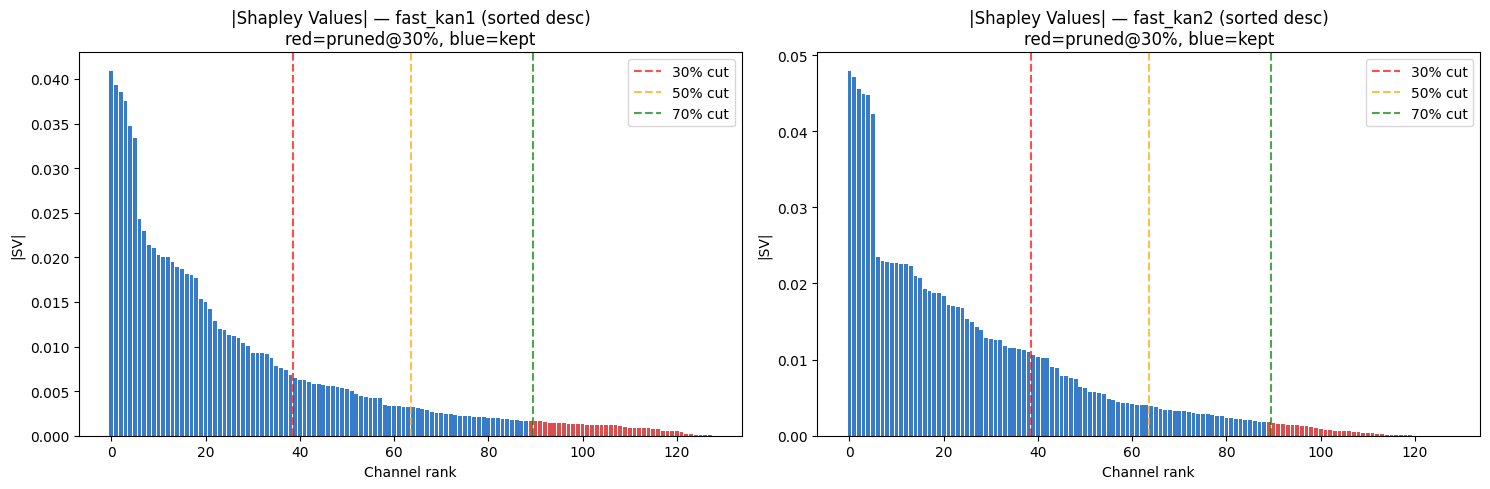


✓ ShapKAN complete.


In [30]:
# ============================================================
# FAST ShapKAN — GKANSU_Improved (FastKAN)
# Adapted from: github.com/YuanJrShiuan/KAN_Pruning_Shapley
# ============================================================

import numpy as np
import torch
import copy
import math
from itertools import combinations
from skimage.metrics import mean_squared_error
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ── PARAMETERS ───────────────────────────────────────────────────────────────
N_PERMUTATIONS  = 32
BATCH_SIZE_SV   = 4
HIDDEN_DIM      = 128
DO_FINETUNE     = True
FINETUNE_EPOCHS = 10
PRUNE_RATIOS    = [0.30, 0.40, 0.50, 0.70, 0.80, 0.90]
ALPHA_SAM       = 0.7
ALPHA_MSE       = 0.3

# ── Pre-load ONE calibration batch ───────────────────────────────────────────
print("Pre-loading calibration batch...")
_calib_iter = iter(train_loader)
calib_graph, calib_hr = next(_calib_iter)
calib_graph = calib_graph.to(device)
calib_hr    = calib_hr.to(device)
print(f"  Calib batch: graph.x={calib_graph.x.shape}, hr={calib_hr.shape}")

# ===========================================================
# METRIC FUNCTIONS
# ===========================================================

def spectral_angle_mapper_np(img1, img2):
    a      = img1.reshape(-1, img1.shape[-1]).astype(np.float64)
    b      = img2.reshape(-1, img2.shape[-1]).astype(np.float64)
    norm_a = np.linalg.norm(a, axis=1, keepdims=True)
    norm_b = np.linalg.norm(b, axis=1, keepdims=True)
    dot    = np.sum(a * b, axis=1, keepdims=True)
    cos    = np.clip(dot / (norm_a * norm_b + 1e-8), -1.0, 1.0)
    return float(np.mean(np.arccos(cos)))

def ssim_per_band(img1, img2):
    C1, C2 = (0.01)**2, (0.03)**2
    scores = []
    for c in range(img1.shape[-1]):
        a            = img1[..., c].ravel().astype(np.float64)
        b            = img2[..., c].ravel().astype(np.float64)
        mu_a, mu_b   = a.mean(), b.mean()
        var_a, var_b = a.var(), b.var()
        cov          = np.mean((a - mu_a) * (b - mu_b))
        num          = (2*mu_a*mu_b + C1) * (2*cov + C2)
        den          = (mu_a**2 + mu_b**2 + C1) * (var_a + var_b + C2)
        scores.append(num / den)
    return float(np.mean(scores))

def evaluate_model_full(model, test_loader, device):
    model.eval()
    sam_list, rmse_list, ssim_list = [], [], []
    with torch.no_grad():
        for graph_data, hr_img in test_loader:
            graph_data = graph_data.to(device)
            hr_img     = hr_img.to(device)
            sr_img     = model(graph_data.x, graph_data.edge_index)
            sr_img     = sr_img.view(hr_img.shape)
            for i in range(sr_img.shape[0]):
                sr_np = sr_img[i].cpu().numpy().transpose(1, 2, 0)
                hr_np = hr_img[i].cpu().numpy().transpose(1, 2, 0)
                sam_list.append(spectral_angle_mapper_np(sr_np, hr_np))
                rmse_list.append(float(np.sqrt(mean_squared_error(hr_np, sr_np))))
                ssim_list.append(ssim_per_band(sr_np, hr_np))
    return {
        "SAM":  float(np.mean(sam_list)),
        "RMSE": float(np.mean(rmse_list)),
        "SSIM": float(np.mean(ssim_list)),
        "SSR":  float(1.0 - np.mean(ssim_list)),
    }

# ===========================================================
# VALUE FUNCTION — pre-loaded single calib batch
# ===========================================================

def value_function_fastkan(model, layer_name, channel_mask,
                            calib_graph, calib_hr, device):
    """
    v(S) — forward pass with hook zeroing channels NOT in coalition S.
    Empty coalition → 0.0  (paper Efficiency axiom).
    """
    if not np.any(channel_mask):
        return 0.0

    mask_t = torch.tensor(channel_mask, dtype=torch.float32, device=device)

    def hook_fn(module, inp, out):
        return out * mask_t.view(1, -1, 1, 1)

    handle = getattr(model, layer_name).register_forward_hook(hook_fn)
    model.eval()
    with torch.no_grad():
        sr_img      = model(calib_graph.x, calib_graph.edge_index)
        sr_img      = sr_img.view(calib_hr.shape)
        B, C, H, W  = calib_hr.shape
        hr_f        = calib_hr.view(B, C, -1)
        sr_f        = sr_img.view(B, C, -1)
        dot         = torch.sum(hr_f * sr_f, dim=1, keepdim=True)
        hn          = torch.norm(hr_f, dim=1, keepdim=True)
        sn          = torch.norm(sr_f, dim=1, keepdim=True)
        cos         = torch.clamp(dot / (hn * sn + 1e-8), -1.0, 1.0)
        sam_val     = torch.acos(cos).mean().item()
    handle.remove()
    return sam_val

# ===========================================================
# PERMUTATION GENERATOR — exact GitHub _gen_permutations()
# ===========================================================

def _gen_permutations(bsz, d, rng, antithetical):
    if not antithetical:
        return np.argsort(rng.random((bsz, d)), axis=1)
    if bsz == 1:
        return np.argsort(rng.random((1, d)), axis=1)
    half  = bsz // 2
    base  = np.argsort(rng.random((half, d)), axis=1)
    perms = np.empty((bsz, d), dtype=int)
    perms[:half]       = base
    perms[half:2*half] = base[:, ::-1]          # antithetic pair
    if bsz % 2 == 1:
        perms[-1] = np.argsort(rng.random((1, d)), axis=1)[0]
    return perms

# ===========================================================
# EXACT SHAPLEY — n < 8  (GitHub: shapley_value_actual)
# ===========================================================

def shapley_value_actual_fastkan(model, layer_name, n_channels,
                                  calib_graph, calib_hr, device):
    node_id_list = list(range(n_channels))
    value_cache  = {}
    sv = []
    for i in node_id_list:
        phi_i    = 0.0
        filtered = [x for x in node_id_list if x != i]
        for r in range(len(filtered) + 1):
            for subset in combinations(filtered, r):
                subset      = list(subset)
                sv_weight   = 1.0 / math.comb(n_channels - 1, len(subset))
                key_without = tuple(sorted(subset))
                if key_without not in value_cache:
                    mask = np.zeros(n_channels, dtype=bool)
                    for idx in subset:
                        mask[idx] = True
                    value_cache[key_without] = value_function_fastkan(
                        model, layer_name, mask, calib_graph, calib_hr, device)
                v_without   = value_cache[key_without]
                subset_with = subset + [i]
                key_with    = tuple(sorted(subset_with))
                if key_with not in value_cache:
                    mask = np.zeros(n_channels, dtype=bool)
                    for idx in subset_with:
                        mask[idx] = True
                    value_cache[key_with] = value_function_fastkan(
                        model, layer_name, mask, calib_graph, calib_hr, device)
                phi_i += sv_weight * (value_cache[key_with] - v_without)
        phi_i /= n_channels
        sv.append(phi_i)
    return sv

# ===========================================================
# APPROXIMATE SHAPLEY — GitHub: shapley_value_approx()
# Eq. 8/9 antithetic permutation sampling + Welford mean
# ===========================================================

def shapley_value_approx_fastkan(model, layer_name, n_channels,
                                  calib_graph, calib_hr, device,
                                  n_permutations=32,
                                  antithetical=True,
                                  seed=42,
                                  batch_size=4):
    d           = n_channels
    rng         = np.random.default_rng(seed)
    values      = np.zeros(d, dtype=float)
    sum_squares = np.zeros(d, dtype=float)
    n           = 0
    value_cache = {}

    # Cache full-coalition value once
    full_key  = tuple(range(d))
    full_mask = np.ones(d, dtype=bool)
    full_pred = value_function_fastkan(model, layer_name, full_mask,
                                        calib_graph, calib_hr, device)
    value_cache[full_key] = full_pred

    n_loops  = int(np.ceil(n_permutations / batch_size))
    iterator = tqdm(range(n_loops), desc=f"ShapKAN [{layer_name}]")

    for it in iterator:
        bsz = min(batch_size, n_permutations - it * batch_size)
        if bsz <= 0:
            break

        permutations = _gen_permutations(bsz, d, rng, antithetical)
        S            = np.zeros((bsz, d), dtype=bool)
        prev_values  = np.zeros(bsz, dtype=float)    # v(∅) = 0
        deltas       = np.zeros((bsz, d), dtype=float)

        for pos in range(d):
            row_idx = np.arange(bsz)
            col_idx = permutations[:, pos]
            S[row_idx, col_idx] = True

            next_values = np.zeros(bsz, dtype=float)
            for k in range(bsz):
                subset_key = tuple(sorted(np.where(S[k])[0]))
                if subset_key not in value_cache:
                    if len(subset_key) == d:
                        value_cache[subset_key] = full_pred
                    else:
                        mask = np.zeros(d, dtype=bool)
                        for idx in subset_key:
                            mask[idx] = True
                        value_cache[subset_key] = value_function_fastkan(
                            model, layer_name, mask,
                            calib_graph, calib_hr, device)
                next_values[k] = value_cache[subset_key]

            deltas[row_idx, col_idx] = next_values - prev_values
            prev_values = next_values

        # Welford online update
        for i in range(bsz):
            n      += 1
            delta   = deltas[i] - values
            values += delta / n
            sum_squares += delta * (deltas[i] - values)

        iterator.set_postfix({'cache_size': len(value_cache), 'n': n})

    return values.tolist()

# ===========================================================
# NODE SELECTION
# ===========================================================

def _get_bottom_percent_positions(data, percent):
    data = np.array(data)
    k    = int(np.ceil(len(data) * percent))
    return np.argsort(data)[:k].tolist()

def keep_mask_from_sv(shapley_vals, prune_ratio, n_channels):
    abs_sv    = np.array([abs(v) for v in shapley_vals])
    prune_idx = set(_get_bottom_percent_positions(abs_sv.tolist(), prune_ratio))
    return np.array([i not in prune_idx for i in range(n_channels)])

def apply_permanent_hook(model, layer_name, keep_mask):
    mask_t = torch.tensor(keep_mask, dtype=torch.float32)
    def hook(module, inp, out):
        return out * mask_t.to(out.device).view(1, -1, 1, 1)
    return getattr(model, layer_name).register_forward_hook(hook)

# ===========================================================
# FINETUNING — combined SAM+MSE loss + weight_decay + scheduler
# ===========================================================

def finetune_model(model, train_loader, device,
                   epochs=10, lr=1e-4,
                   alpha_sam=ALPHA_SAM, alpha_mse=ALPHA_MSE):
    def combined_loss(hr, sr):
        B, C, H, W = hr.shape
        hf   = hr.view(B, C, -1)
        sf   = sr.view(B, C, -1)
        dot  = torch.sum(hf * sf, dim=1, keepdim=True)
        hn   = torch.norm(hf, dim=1, keepdim=True)
        sn   = torch.norm(sf, dim=1, keepdim=True)
        cos  = torch.clamp(dot / (hn * sn + 1e-8), -1.0, 1.0)
        l_sam = torch.acos(cos).mean()
        l_mse = torch.nn.functional.mse_loss(sr, hr)
        return alpha_sam * l_sam + alpha_mse * l_mse

    model.train()
    opt       = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt, mode='min', factor=0.5, patience=2)

    for ep in range(epochs):
        total = 0.0
        for graph_data, hr_imgs in train_loader:
            graph_data = graph_data.to(device)
            hr_imgs    = hr_imgs.to(device)
            opt.zero_grad()
            sr   = model(graph_data.x, graph_data.edge_index).view(hr_imgs.shape)
            loss = combined_loss(hr_imgs, sr)
            loss.backward()
            opt.step()
            total += loss.item()
        avg = total / len(train_loader)
        scheduler.step(avg)
        print(f"  [FT {ep+1}/{epochs}] loss: {avg:.4f}")

# ===========================================================
# MAIN SWEEP
# ===========================================================

# ── Reload clean checkpoint before baseline (matches Taylor/KAN-KO) ──────────
CHECKPOINT = '/content/drive/MyDrive/GKANSU/model_checkpoint.pth'
model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
model.to(device)
model.eval()
print(f"✓ Reloaded clean checkpoint from {CHECKPOINT}")

print("=" * 65)
print("BASELINE — before pruning")
print("=" * 65)
baseline = evaluate_model_full(model, test_loader, device)
print(f"  SAM : {baseline['SAM']:.4f}")
print(f"  RMSE: {baseline['RMSE']:.4f}")
print(f"  SSIM: {baseline['SSIM']:.4f}")
print(f"  SSR : {baseline['SSR']:.4f}")


# ── Baseline ──────────────────────────────────────────────────────────────────
print("=" * 65)
print("BASELINE — before pruning")
print("=" * 65)
baseline = evaluate_model_full(model, test_loader, device)
print(f"  SAM : {baseline['SAM']:.4f}")
print(f"  RMSE: {baseline['RMSE']:.4f}")
print(f"  SSIM: {baseline['SSIM']:.4f}")
print(f"  SSR : {baseline['SSR']:.4f}")

# ── SV Estimation — fast_kan1 ─────────────────────────────────────────────────
print("\n" + "=" * 65)
print("ShapKAN SV — fast_kan1  (l=1, bottom-up)")
print("=" * 65)
if HIDDEN_DIM < 8:
    sv_kan1 = shapley_value_actual_fastkan(
        model, 'fast_kan1', HIDDEN_DIM, calib_graph, calib_hr, device)
else:
    sv_kan1 = shapley_value_approx_fastkan(
        model, 'fast_kan1', HIDDEN_DIM,
        calib_graph, calib_hr, device,
        n_permutations=N_PERMUTATIONS,
        antithetical=True, seed=42,
        batch_size=BATCH_SIZE_SV)
abs_sv1 = np.abs(sv_kan1)
print(f"  min={abs_sv1.min():.5f}  max={abs_sv1.max():.5f}  mean={abs_sv1.mean():.5f}")

# ── SV Estimation — fast_kan2 ─────────────────────────────────────────────────
print("\n" + "=" * 65)
print("ShapKAN SV — fast_kan2  (l=2)")
print("=" * 65)
if HIDDEN_DIM < 8:
    sv_kan2 = shapley_value_actual_fastkan(
        model, 'fast_kan2', HIDDEN_DIM, calib_graph, calib_hr, device)
else:
    sv_kan2 = shapley_value_approx_fastkan(
        model, 'fast_kan2', HIDDEN_DIM,
        calib_graph, calib_hr, device,
        n_permutations=N_PERMUTATIONS,
        antithetical=True, seed=42,
        batch_size=BATCH_SIZE_SV)
abs_sv2 = np.abs(sv_kan2)
print(f"  min={abs_sv2.min():.5f}  max={abs_sv2.max():.5f}  mean={abs_sv2.mean():.5f}")

# ── Pruning Sweep ─────────────────────────────────────────────────────────────
results = []
print("\n" + "=" * 65)
print("Pruning Sweep")
print("=" * 65)
print(f"{'Ratio':>6} | {'%Pruned':>7} | {'SAM_noFT':>9} | {'SAM_FT':>7} | "
      f"{'RMSE':>7} | {'SSIM':>7} | {'SSR':>7} | {'ΔSAM':>7} | {'ΔRMSE':>7}")
print("-" * 80)

for ratio in PRUNE_RATIOS:
    pruned_model = copy.deepcopy(model).to(device)

    keep1      = keep_mask_from_sv(sv_kan1, ratio, HIDDEN_DIM)
    keep2      = keep_mask_from_sv(sv_kan2, ratio, HIDDEN_DIM)
    n_pruned   = int((~keep1).sum()) + int((~keep2).sum())
    pct_pruned = 100.0 * n_pruned / (HIDDEN_DIM * 2)

    h1 = apply_permanent_hook(pruned_model, 'fast_kan1', keep1)
    h2 = apply_permanent_hook(pruned_model, 'fast_kan2', keep2)

    m_no_ft = evaluate_model_full(pruned_model, test_loader, device)

    if DO_FINETUNE:
        print(f"  [ratio={ratio:.0%}] Finetuning...")
        finetune_model(pruned_model, train_loader, device,
                       epochs=FINETUNE_EPOCHS, lr=1e-4)
        m_ft = evaluate_model_full(pruned_model, test_loader, device)
    else:
        m_ft = m_no_ft

    #h1.remove()
    #h2.remove()

    results.append({
        'ratio':      ratio,
        'pct_pruned': pct_pruned,
        # no-finetune — all 4 metrics stored (needed for plots)
        'SAM_no_ft':  m_no_ft['SAM'],
        'RMSE_no_ft': m_no_ft['RMSE'],
        'SSIM_no_ft': m_no_ft['SSIM'],
        'SSR_no_ft':  m_no_ft['SSR'],
        # after finetune
        'SAM_ft':     m_ft['SAM'],
        'RMSE_ft':    m_ft['RMSE'],
        'SSIM_ft':    m_ft['SSIM'],
        'SSR_ft':     m_ft['SSR'],
        'delta_SAM':  m_ft['SAM']  - baseline['SAM'],
        'delta_RMSE': m_ft['RMSE'] - baseline['RMSE'],
        'keep1':      keep1,
        'keep2':      keep2,
    })

    print(f"{ratio:>6.0%} | {pct_pruned:>6.1f}% | {m_no_ft['SAM']:>9.4f} | "
          f"{m_ft['SAM']:>7.4f} | {m_ft['RMSE']:>7.4f} | {m_ft['SSIM']:>7.4f} | "
          f"{m_ft['SSR']:>7.4f} | {results[-1]['delta_SAM']:>+7.4f} | "
          f"{results[-1]['delta_RMSE']:>+7.4f}")

# ── Summary ───────────────────────────────────────────────────────────────────
print("\n" + "=" * 65)
print("FINAL SUMMARY")
print("=" * 65)
print(f"Baseline SAM={baseline['SAM']:.4f}  RMSE={baseline['RMSE']:.4f}  "
      f"SSIM={baseline['SSIM']:.4f}  SSR={baseline['SSR']:.4f}\n")
print(f"{'Ratio':>6} | {'SAM':>7} | {'RMSE':>7} | {'SSIM':>7} | "
      f"{'SSR':>7} | {'ΔSAM':>7} | {'ΔRMSE':>7}")
print("-" * 60)
for r in results:
    print(f"{r['ratio']:>6.0%} | {r['SAM_ft']:>7.4f} | {r['RMSE_ft']:>7.4f} | "
          f"{r['SSIM_ft']:>7.4f} | {r['SSR_ft']:>7.4f} | "
          f"{r['delta_SAM']:>+7.4f} | {r['delta_RMSE']:>+7.4f}")

# ── Metric Plots ──────────────────────────────────────────────────────────────
ratios_pct = [r['ratio'] * 100 for r in results]
fig, axes  = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('ShapKAN Pruning Results — GKANSU_Improved',
             fontsize=13, fontweight='bold')

plot_cfg = [
    ('SAM_ft',  'SAM_no_ft',  'SAM (↓ better)',  'SAM',  baseline['SAM']),
    ('RMSE_ft', 'RMSE_no_ft', 'RMSE (↓ better)', 'RMSE', baseline['RMSE']),
    ('SSIM_ft', 'SSIM_no_ft', 'SSIM (↑ better)', 'SSIM', baseline['SSIM']),
    ('SSR_ft',  'SSR_no_ft',  'SSR (↓ better)',  'SSR',  baseline['SSR']),
]

for ax, (key_ft, key_noft, title, ylabel, bval) in zip(axes.flat, plot_cfg):
    ax.plot(ratios_pct, [r[key_noft] for r in results],
            'o--', color='orange', label='No Finetune', linewidth=1.5)
    ax.plot(ratios_pct, [r[key_ft] for r in results],
            's-', color='steelblue', label='With Finetune', linewidth=2)
    ax.axhline(bval, color='red', linestyle=':',
               linewidth=1.5, label=f'Baseline ({bval:.4f})')
    ax.set_title(title)
    ax.set_xlabel('Prune Ratio (%)')
    ax.set_ylabel(ylabel)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ── SV Distribution Plot (sorted descending) ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, sv_raw, name in zip(axes, [sv_kan1, sv_kan2], ['fast_kan1', 'fast_kan2']):
    abs_sv    = np.abs(sv_raw)
    sort_idx  = np.argsort(abs_sv)[::-1]          # descending
    sorted_sv = abs_sv[sort_idx]

    # Mark which sorted positions correspond to bottom-30% (pruned)
    prune_30_orig = set(_get_bottom_percent_positions(abs_sv.tolist(), 0.30))
    sorted_prune  = set(np.where(np.isin(sort_idx, list(prune_30_orig)))[0])
    colors        = ['#d32f2f' if i in sorted_prune else '#1565c0'
                     for i in range(HIDDEN_DIM)]

    ax.bar(range(HIDDEN_DIM), sorted_sv, color=colors, alpha=0.85)

    # Vertical cut lines at 30/50/70%
    for pct, col, lbl in [(0.30, 'red',    '30% cut'),
                           (0.50, 'orange', '50% cut'),
                           (0.70, 'green',  '70% cut')]:
        cut = int(np.ceil(HIDDEN_DIM * pct))
        ax.axvline(cut - 0.5, color=col, linestyle='--', alpha=0.7, label=lbl)

    ax.set_title(f'|Shapley Values| — {name} (sorted desc)\nred=pruned@30%, blue=kept')
    ax.set_xlabel('Channel rank')
    ax.set_ylabel('|SV|')
    ax.legend()

plt.tight_layout()
plt.show()

print("\n✓ ShapKAN complete.")

In [33]:
# ============================================================
# PARAMETER COUNT BREAKDOWN — GKANSU_Improved
# ============================================================
import pandas as pd

def count_params(module):
    total = sum(p.numel() for p in module.parameters())
    trainable = sum(p.numel() for p in module.parameters() if p.requires_grad)
    return total, trainable

components = {
    'input_proj':       model.input_proj,
    'gat_layers':       model.gat_layers,
    'batch_norms':      model.batch_norms,
    'fast_kan1':        model.fast_kan1,
    'fast_kan2':        model.fast_kan2,
    'ssa':              model.ssa,
    'final_refinement':  model.final_refinement,
}

rows = []
grand_total = 0
for name, module in components.items():
    total, trainable = count_params(module)
    grand_total += total
    rows.append({
        'Component': name,
        'Total Params': total,
        'Trainable Params': trainable,
        '% of Model': None  # filled in after we know grand_total
    })

# whole-model total (sanity check — should equal grand_total above)
model_total, model_trainable = count_params(model)

for r in rows:
    r['% of Model'] = round(100 * r['Total Params'] / model_total, 2)

df = pd.DataFrame(rows)
df = df.sort_values('Total Params', ascending=False).reset_index(drop=True)

print(df.to_string(index=False))
print(f"\nSum of listed components : {grand_total:,}")
print(f"Model total (all params)  : {model_total:,}")
print(f"Model trainable params    : {model_trainable:,}")

if grand_total != model_total:
    print(f"\n⚠️ Mismatch of {model_total - grand_total:,} params — model has parameters "
          f"outside the listed components (check for missed submodules).")

df.to_csv('gkan_param_breakdown.csv', index=False)
print("\nSaved: gkan_param_breakdown.csv")

       Component  Total Params  Trainable Params  % of Model
final_refinement       2073601           2073601       41.36
       fast_kan1       1327112           1327104       26.47
       fast_kan2       1327112           1327104       26.47
      gat_layers        200064            200064        3.99
             ssa         82112             82112        1.64
      input_proj          2688              2688        0.05
     batch_norms           768               768        0.02

Sum of listed components : 5,013,457
Model total (all params)  : 5,013,457
Model trainable params    : 5,013,441

Saved: gkan_param_breakdown.csv


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error

def spectral_angle_mapper(img1, img2):
    """
    Compute the Spectral Angle Mapper (SAM) between two images.
    img1 and img2 should have shape (H, W, C) where C is the number of spectral bands.
    """
    img1_flat = img1.reshape(-1, img1.shape[-1])
    img2_flat = img2.reshape(-1, img2.shape[-1])

    # Normalize to unit vectors
    norm_img1 = np.linalg.norm(img1_flat, axis=1, keepdims=True)
    norm_img2 = np.linalg.norm(img2_flat, axis=1, keepdims=True)

    dot_product = np.sum(img1_flat * img2_flat, axis=1, keepdims=True)
    sam_values = np.arccos(np.clip(dot_product / (norm_img1 * norm_img2 + 1e-8), -1, 1))

    return np.mean(sam_values)  # Return the average SAM value over all pixels

def test_and_visualize(model, test_loader, device='cpu'):
    model.eval()
    sam_values, rmse_values = [], []

    with torch.no_grad():
        for graph_data, hr_img in test_loader:
            graph_data, hr_img = graph_data.to(device), hr_img.to(device)

            # Extract node features and edge index from graph_data
            sr_img = model(graph_data.x, graph_data.edge_index)  # Corrected model input

            # Reshape SR Image to (Batch, Channels, Height, Width)
            sr_img = sr_img.view(hr_img.shape)

            # Move tensors to CPU for visualization
            sr_img_np = sr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)
            hr_img_np = hr_img[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)

            # Calculate RMSE and SAM
            rmse_value = np.sqrt(mean_squared_error(hr_img_np, sr_img_np))
            sam_value = spectral_angle_mapper(hr_img_np, sr_img_np)

            rmse_values.append(rmse_value)
            sam_values.append(sam_value)

            # Plot images
            fig, axs = plt.subplots(1, 2, figsize=(10, 5))
            %) are correctly sitting at the tail end where values are near zero. That validates the Shapley ranking is meaningful.

The metric plots confirm the story — blue (with finetune) stays flat and low across all ratios, well below axs[0].imshow(sr_img_np[:, :, 127], cmap='viridis')
            axs[0].set_title(f"Super-Resolved (SR)\nRMSE: {rmse_value:.4f}, SAM: {sam_value:.4f}")
            axs[0].axis('off')

            axs[1].imshow(hr_img_np[:, :, 127], cmap='viridis')
            axs[1].set_title("High Resolution (HR)")
            axs[1].axis('off')

            plt.show()
            break  # Display only first batch

    print(f"Average RMSE: {sum(rmse_values) / len(rmse_values):.4f}")
    print(f"Average SAM: {sum(sam_values) / len(sam_values):.4f}")

# Test and visualize results
test_and_visualize(model, test_loader, device)

In [ ]:
import requests, os

os.makedirs('datasets', exist_ok=True)

# These are the actual direct file URLs from EHU wiki
# Sometimes they work even when the main page is down
urls = {
    'datasets/Indian_pines_corrected.mat': 'http://www.ehu.eus/ccwintco/uploads/6/67/Indian_pines_corrected.mat',
    'datasets/Indian_pines_gt.mat':        'http://www.ehu.eus/ccwintco/uploads/c/c4/Indian_pines_gt.mat',
}

for path, url in urls.items():
    print(f'Trying {url}...')
    try:
        r = requests.get(url, timeout=30)
        if r.status_code == 200:
            with open(path, 'wb') as f:
                f.write(r.content)
            print(f'  OK — {len(r.content)/1024:.0f} KB saved')
        else:
            print(f'  Failed: status {r.status_code}')
    except Exception as e:
        print(f'  Error: {e}')